In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## linear_homo_gaussian 분석

In [2]:
# 노트북을 어디서 실행하든 `시뮬.md`가 있는 폴더를 프로젝트 루트로 사용한다.
PROJECT_ROOT = None
for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / '시뮬.md').exists():
        PROJECT_ROOT = folder
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('시뮬.md가 있는 프로젝트 루트를 찾지 못했습니다.')

SCENARIO = 'linear_homo_gaussian'
RESULT_DIR = PROJECT_ROOT / 'results' / SCENARIO

# grid·alpha·method별 coverage가 들어 있는 집계표
point_summary = pd.read_csv(RESULT_DIR / 'point_summary.csv')

print('PROJECT_ROOT:', PROJECT_ROOT)
print('point_summary:', point_summary.shape)
display(point_summary) # grid 25개 * 4(method(MC/CP) * alpha(0.05/0.1))

PROJECT_ROOT: C:\Users\cho03\Desktop\조민석\연구
point_summary: (100, 11)


,scenario,grid_id,x1,x2,alpha,method,n_covered,n_evaluated,coverage,length_mean,length_sd
0,linear_homo_gaussian,0,-1.0,-1.0,0.10,mc,174,200,0.870,3.329880,0.200263
1,linear_homo_gaussian,0,-1.0,-1.0,0.10,cp,180,200,0.900,3.348946,0.088993
2,linear_homo_gaussian,0,-1.0,-1.0,0.05,mc,190,200,0.950,3.947480,0.253131
3,linear_homo_gaussian,0,-1.0,-1.0,0.05,cp,189,200,0.945,3.994759,0.121433
4,linear_homo_gaussian,1,-1.0,-0.5,0.10,mc,178,200,0.890,3.370823,0.238562
...,...,...,...,...,...,...,...,...,...,...,...
95,linear_homo_gaussian,23,1.0,0.5,0.05,cp,188,200,0.940,3.994759,0.121433
96,linear_homo_gaussian,24,1.0,1.0,0.10,mc,176,200,0.880,3.353631,0.202701
97,linear_homo_gaussian,24,1.0,1.0,0.10,cp,184,200,0.920,3.348946,0.088993
98,linear_homo_gaussian,24,1.0,1.0,0.05,mc,188,200,0.940,3.982816,0.265947


In [3]:
# 입력 좌표를 '[x1, x2]' 문자열로 만들어 표의 행 이름으로 쓴다.
point_summary['x'] = '[' + point_summary['x1'].astype(str) + ', ' + point_summary['x2'].astype(str) + ']'

# 목표 coverage와의 차이: coverage - (1 - alpha). 음수면 목표보다 덜 덮음.
point_summary['coverage_gap'] = point_summary['coverage'] - (1 - point_summary['alpha'])

# alpha = 0.10 : 행은 grid 25개, 열은 method(mc, cp)의 coverage - 0.90
summary_010 = point_summary[point_summary['alpha'] == 0.10]
gap_010 = summary_010.pivot(index=['grid_id', 'x'], columns='method', values='coverage_gap')
gap_010 = gap_010[['mc', 'cp']].round(3)
print('alpha = 0.10 : coverage - 0.90')
gap_010

alpha = 0.10 : coverage - 0.90


,method,mc,cp
grid_id,x,,
0,"[-1.0, -1.0]",-0.030,0.000
1,"[-1.0, -0.5]",-0.010,0.005
2,"[-1.0, 0.0]",0.010,0.000
3,"[-1.0, 0.5]",-0.045,-0.030
4,"[-1.0, 1.0]",0.015,0.010
5,"[-0.5, -1.0]",0.015,0.050
6,"[-0.5, -0.5]",-0.015,-0.005
7,"[-0.5, 0.0]",-0.015,0.000
8,"[-0.5, 0.5]",0.025,0.030


In [4]:
# alpha = 0.05 : 같은 형식, coverage - 0.95
summary_005 = point_summary[point_summary['alpha'] == 0.05]
gap_005 = summary_005.pivot(index=['grid_id', 'x'], columns='method', values='coverage_gap')
gap_005 = gap_005[['mc', 'cp']].round(3)
print('alpha = 0.05 : coverage - 0.95')
gap_005

alpha = 0.05 : coverage - 0.95


,method,mc,cp
grid_id,x,,
0,"[-1.0, -1.0]",0.000,-0.005
1,"[-1.0, -0.5]",-0.025,-0.010
2,"[-1.0, 0.0]",0.000,0.005
3,"[-1.0, 0.5]",-0.030,-0.010
4,"[-1.0, 1.0]",0.000,0.010
5,"[-0.5, -1.0]",0.015,0.015
6,"[-0.5, -0.5]",-0.020,0.000
7,"[-0.5, 0.0]",-0.005,-0.005
8,"[-0.5, 0.5]",-0.005,0.010


### grid별 coverage − (1 − α) 색 그림

가로축 $x_1$, 세로축 $x_2$의 5×5 격자에서 각 칸의 색이 그 입력의 $\widehat c(x_i) - (1-\alpha)$이다. 0(흰색)이면 목표 coverage와 같고, 음수(빨강)면 목표보다 덜 덮고, 양수(파랑)면 더 덮는다. 칸 안 숫자는 그 차이 값이다. 각 coverage는 R=200 반복의 평균이므로, 목표가 0.90일 때 우연만으로도 약 ±0.02(표준오차) 정도 흔들린다.

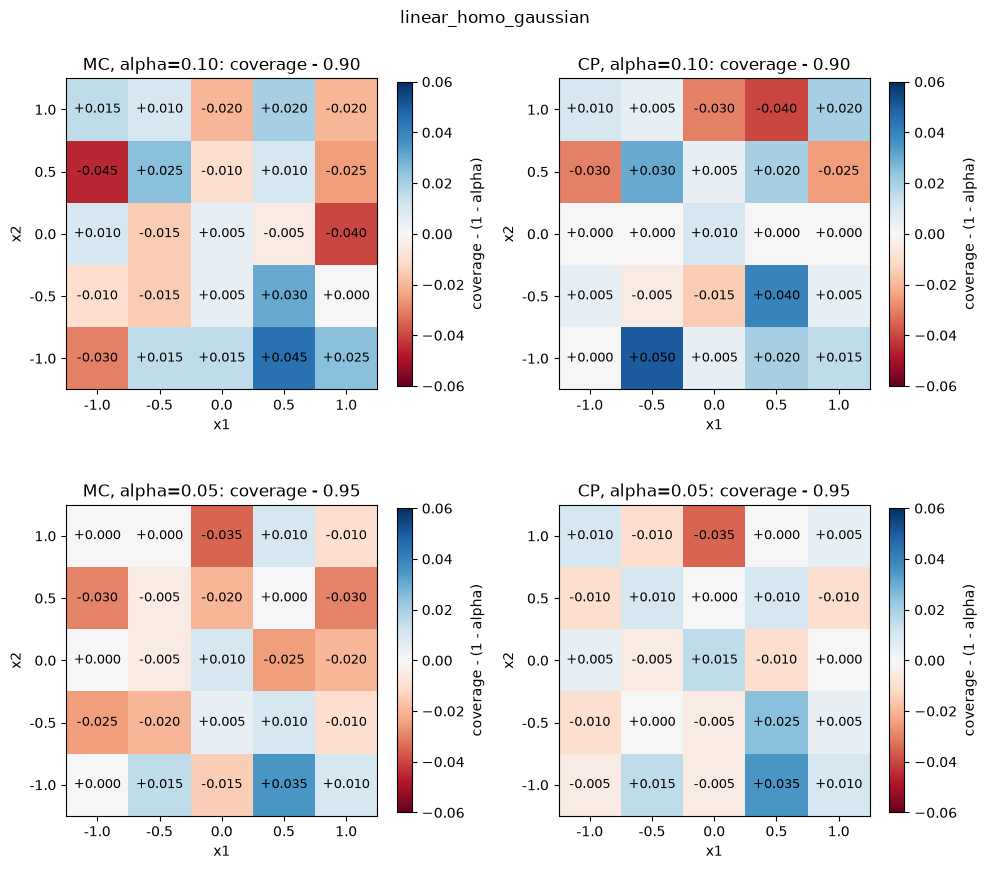

In [5]:
# 색 범위: 0을 가운데로 두고 위아래 같은 폭 (네 그림 모두 같은 범위라 색을 바로 비교할 수 있다)
COLOR_HALF_WIDTH = 0.06

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for row, alpha in enumerate([0.10, 0.05]):
    target = 1 - alpha
    for col, method in enumerate(['mc', 'cp']):
        ax = axes[row, col]
        part = point_summary[(point_summary['alpha'] == alpha) & (point_summary['method'] == method)]

        # 행 = x2, 열 = x1 인 5x5 행렬 (origin='lower'로 x2가 아래에서 위로 커지게 그림)
        table = part.pivot(index='x2', columns='x1', values='coverage_gap')
        x1_values = table.columns.to_numpy()
        x2_values = table.index.to_numpy()

        image = ax.imshow(
            table.to_numpy(),
            origin='lower',
            cmap='RdBu',
            vmin=-COLOR_HALF_WIDTH,
            vmax=COLOR_HALF_WIDTH,
        )

        # 칸마다 차이 값을 부호와 함께 표시
        for i in range(len(x2_values)):
            for j in range(len(x1_values)):
                ax.text(j, i, f'{table.iloc[i, j]:+.3f}', ha='center', va='center', fontsize=9)

        ax.set_xticks(range(len(x1_values)))
        ax.set_xticklabels(x1_values)
        ax.set_yticks(range(len(x2_values)))
        ax.set_yticklabels(x2_values)
        ax.set_xlabel('x1')
        ax.set_ylabel('x2')
        ax.set_title(f'{method.upper()}, alpha={alpha:.2f}: coverage - {target:.2f}')
        fig.colorbar(image, ax=ax, shrink=0.8, label='coverage - (1 - alpha)')

fig.suptitle(SCENARIO)
fig.tight_layout()
plt.show()